# Corrected NEAT speed comparison

Regenerated on 5 November 2026. Compare the same speed-trained g98 genome at 0.50 and 1.50 m/s with the same frozen recovery PID at each cap. The embedded 360 corrected episode summaries reproduce all four report figures. Run all cells with NumPy and Matplotlib in Jupyter.

The corrected evaluator uses a 100 mm corridor, two seconds of departure without sensor contact, corridor-consistent gates, and five seconds without new ordered progress. Error means use exact distance to the intended route polyline.

In [1]:
import base64
from collections import Counter
import gzip
from io import BytesIO
import json
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np

EXPORT_DIR = None  # Set to a Path to also save PNG and SVG files.
BG, INK, MUTED, GRID = "#f6f5f0", "#17262c", "#4c6168", "#d7dfdd"
TEAL, BLUE, CLAY, OCHRE = "#087f72", "#416994", "#ba533c", "#a87516"
PARENT, EARLY, FINAL = "g94-parent", "speed-g00", "speed-g98"
PLAIN, FILTERED = "pid-plain", "pid-filtered"
COMPARATORS = (PARENT, EARLY, FINAL, PLAIN, FILTERED)
TRACE_POLICIES = (PARENT, FINAL, PLAIN, FILTERED)
LABELS = {PARENT: "NEAT g94 (parent)", EARLY: "NEAT g00", FINAL: "NEAT g98",
          PLAIN: "Plain PID", FILTERED: "Filtered PID + recovery"}
COLORS = dict(zip(COMPARATORS, (BLUE, "#795e92", TEAL, CLAY, OCHRE)))
DIFFICULTIES = ("beginner", "intermediate", "advanced")
CAPS = (.50, .65, .80, 1.00, 1.25, 1.50)

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
    "axes.labelcolor": INK, "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "svg.hashsalt": "neat-speed-results"
})

def page(number, title, subtitle, footer, height=5.4):
    fig = plt.figure(figsize=(12, height))
    fig.text(.06, .96, f"SPEED STUDY  /  {number:02d}", va="top", color=TEAL, weight="bold", fontsize=10)
    fig.text(.06, .902, title, va="top", size=22, weight="bold")
    fig.text(.06, .824, subtitle, va="top", color=MUTED, size=11)
    fig.text(.06, .041, footer, va="bottom", color=MUTED, size=9)
    return fig

def save(fig, name):
    png = BytesIO()
    fig.savefig(png, format="png", dpi=160)
    if EXPORT_DIR is not None:
        path = Path(EXPORT_DIR)
        path.mkdir(parents=True, exist_ok=True)
        (path / f"{name}.png").write_bytes(png.getvalue())
        fig.savefig(path / f"{name}.svg", metadata={"Date": None})
    display({"image/png": base64.b64encode(png.getvalue()).decode("ascii"), "text/plain": name},
            raw=True, metadata={"image/png": {"width": 1000}})
    plt.close(fig)

def label(policy):
    return LABELS.get(policy, f"NEAT {policy.removeprefix('speed-')}")

def show_table(headers, rows):
    lines = [headers, ["---"]*len(headers), *rows]
    markdown = "\n".join("| " + " | ".join(row) + " |" for row in lines)
    display({"text/markdown": markdown, "text/plain": markdown}, raw=True, metadata={})
CONDITIONS = (('speed-g98', 0.5), ('pid-filtered', 0.5), ('speed-g98', 1.5), ('pid-filtered', 1.5))

In [2]:
payload = (
    '...'
    'x5h7b9T5gXxnVzy0i8z/+/mPf/wXsaVUWbniAQA='
)
data = json.loads(gzip.decompress(base64.b64decode(payload)))

In [3]:
def group_episodes(records, tracks):
    grouped = {}
    for r in records:
        group = grouped.setdefault((r["policy"], r["cap"]), {})
        assert r["slot"] not in group and not r["error"]
        group[r["slot"]] = r
    for group in grouped.values():
        assert set(group) == set(range(90))
        assert [group[i]["hash"] for i in range(90)] == tracks
        assert Counter(r["difficulty"] for r in group.values()) == dict.fromkeys(DIFFICULTIES, 30)
    return grouped

def describe(group):
    rows = list(group.values())
    finished = [r for r in rows if r["done"]]
    reasons = Counter(r["termination"] for r in rows)
    return {"n": len(rows), "finished": len(finished), "failure_pct": 100*(1-len(finished)/len(rows)),
            **{d: sum(r["difficulty"] == d for r in finished) for d in DIFFICULTIES},
            "rmse_mm": mean(r["rmse"] for r in rows)*1000, "mae_mm": mean(r["mae"] for r in rows)*1000,
            "progress_pct": mean(r["progress"] for r in rows)*100,
            "observed_forward_m_s": mean(r["forward"] for r in rows),
            "finished_time_s": mean(r["elapsed"] for r in finished) if finished else None,
            "off_route": reasons["off_route"], "stalled": reasons["stalled"],
            "other_failures": len(rows)-len(finished)-reasons["off_route"]-reasons["stalled"]}

def pair(first, second):
    assert first.keys() == second.keys()
    rows = [(a, second[i]) for i, a in first.items()]
    shared = [(a, b) for a, b in rows if a["done"] and b["done"]]
    result = {"both_finished": len(shared),
              "first_only": sum(a["done"] and not b["done"] for a, b in rows),
              "second_only": sum(b["done"] and not a["done"] for a, b in rows),
              "neither": sum(not a["done"] and not b["done"] for a, b in rows)}
    for i, side in enumerate(("first", "second")):
        result[f"{side}_rmse_mm"] = mean(p[i]["rmse"] for p in shared)*1000 if shared else None
        result[f"{side}_time_s"] = mean(p[i]["elapsed"] for p in shared) if shared else None
    return result
groups = group_episodes(data['episodes'], data['tracks'])

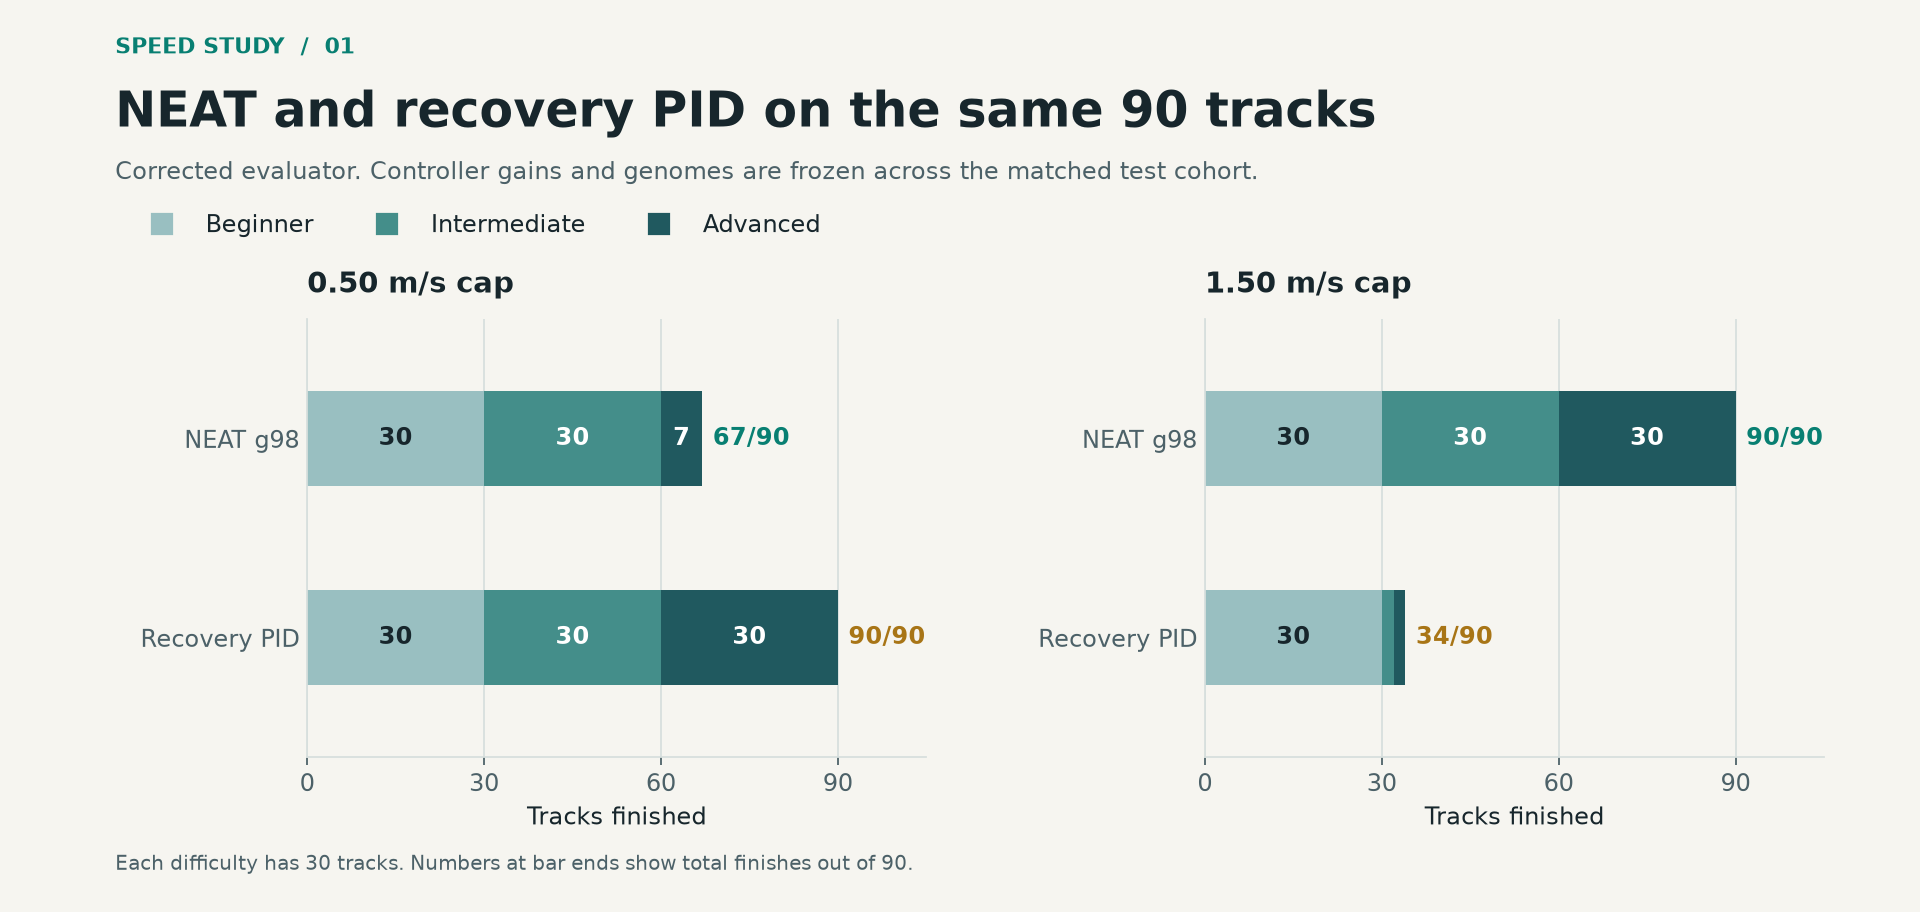

In [4]:
def completion_figure(groups):
    fig = page(1, "NEAT and recovery PID on the same 90 tracks",
               "Corrected evaluator. Controller gains and genomes are frozen across the matched test cohort.",
               "Each difficulty has 30 tracks. Numbers at bar ends show total finishes out of 90.", 5.7)
    axes = fig.add_gridspec(1, 2, left=.16, right=.95, top=.65, bottom=.17, wspace=.45).subplots()
    shades = ("#99bfc1", "#448e8a", "#20595f")
    for ax, (cap, neat) in zip(axes, ((.5, FINAL), (1.5, FINAL))):
        for y, policy in enumerate((neat, FILTERED)):
            r = describe(groups[policy, cap])
            left = 0
            for d, color in zip(DIFFICULTIES, shades):
                n = r[d]
                ax.barh(y, n, left=left, color=color, height=.48)
                if n >= 7:
                    ax.text(left+n/2, y, str(n), ha="center", va="center",
                            color=INK if d == "beginner" else "white", weight="bold")
                left += n
            ax.text(left+1.8, y, f"{left}/90", va="center", weight="bold", color=COLORS[policy])
        ax.set(xlim=(0, 105), xticks=(0, 30, 60, 90), yticks=(0, 1),
               yticklabels=[label(neat), "Recovery PID"], xlabel="Tracks finished", ylim=(1.6, -.6))
        ax.set_title(f"{cap:.2f} m/s cap", loc="left", pad=12)
        ax.set_axisbelow(True)
        ax.grid(axis="x")
        ax.tick_params(axis="y", length=0)
    fig.legend(handles=[Line2D([], [], ls="", marker="s", ms=9, color=c, label=d.title())
                        for d, c in zip(DIFFICULTIES, shades)],
               ncol=3, loc="upper left", bbox_to_anchor=(.06, .79), frameon=False)
    save(fig, "01-corrected-completion")
completion_figure(groups)

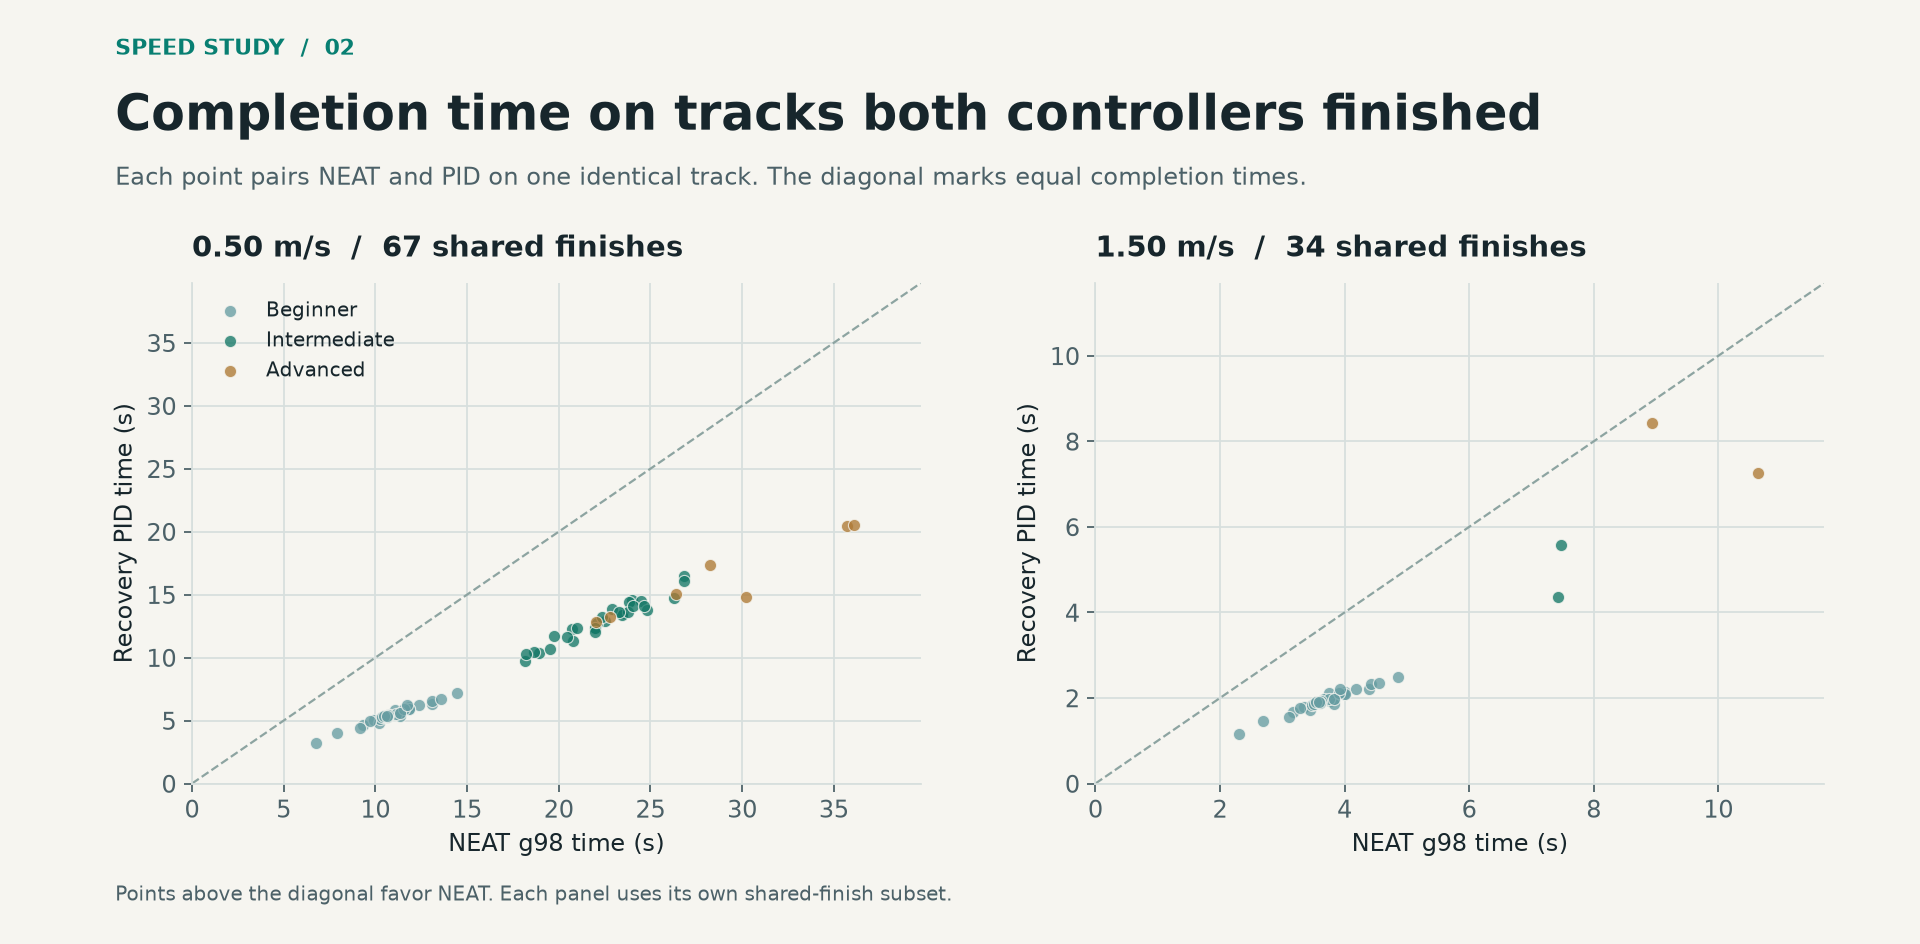

In [5]:
def timing_figure(groups):
    fig = page(2, "Completion time on tracks both controllers finished",
               "Each point pairs NEAT and PID on one identical track. The diagonal marks equal completion times.",
               "Points above the diagonal favor NEAT. Each panel uses its own shared-finish subset.", 5.9)
    axes = fig.add_gridspec(1, 2, left=.10, right=.95, top=.70, bottom=.17, wspace=.24).subplots()
    colors = dict(zip(DIFFICULTIES, ("#679da2", "#147867", "#ae7934")))
    for ax, (cap, neat) in zip(axes, ((.5, FINAL), (1.5, FINAL))):
        pairs = [(a, groups[FILTERED, cap][slot]) for slot, a in groups[neat, cap].items()
                 if a["done"] and groups[FILTERED, cap][slot]["done"]]
        maximum = max(max(a["elapsed"], b["elapsed"]) for a, b in pairs)*1.10
        ax.plot((0, maximum), (0, maximum), ls="--", color="#8da4a1", lw=1)
        for d in DIFFICULTIES:
            points = [(a["elapsed"], b["elapsed"]) for a, b in pairs if a["difficulty"] == d]
            if points:
                x, y = np.array(points).T
                ax.scatter(x, y, s=30, color=colors[d], alpha=.78, edgecolor=BG, linewidth=.5, label=d.title())
        ax.set(xlim=(0, maximum), ylim=(0, maximum), xlabel=f"{label(neat)} time (s)", ylabel="Recovery PID time (s)")
        ax.set_title(f"{cap:.2f} m/s  /  {len(pairs)} shared finishes", loc="left", pad=12)
        ax.set_axisbelow(True)
        ax.grid()
    axes[0].legend(frameon=False, fontsize=9, loc="upper left")
    save(fig, "02-corrected-paired-time")
timing_figure(groups)

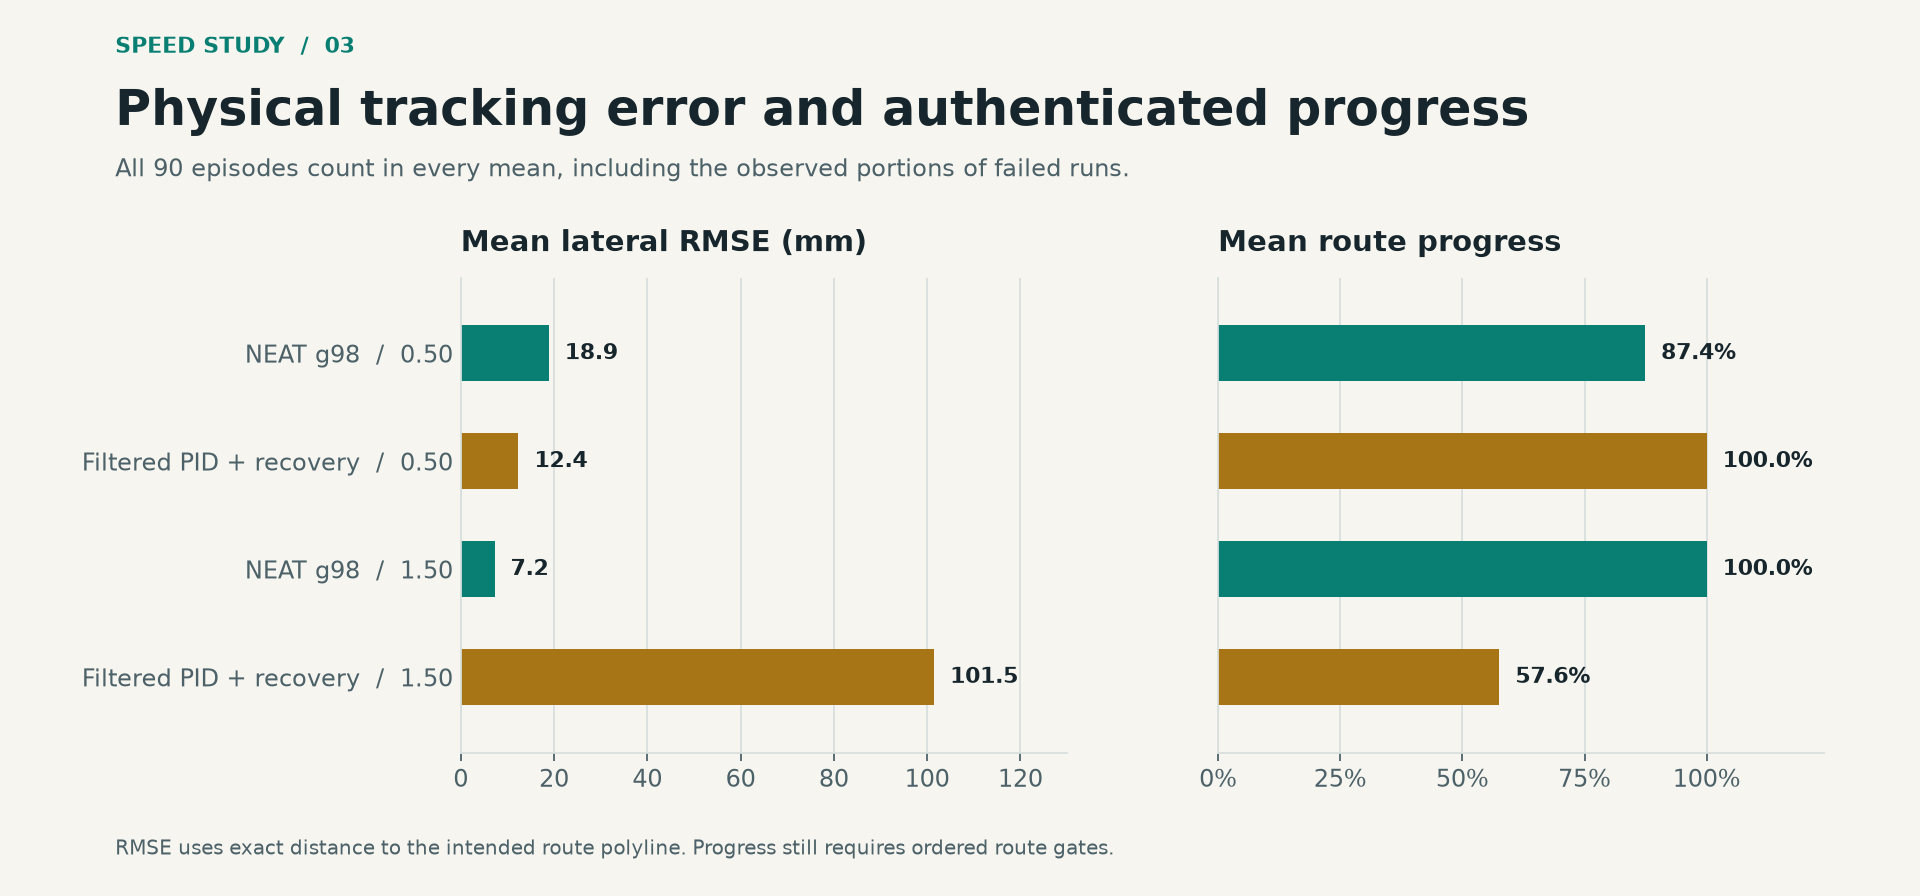

In [6]:
def error_figure(groups):
    fig = page(3, "Physical tracking error and authenticated progress",
               "All 90 episodes count in every mean, including the observed portions of failed runs.",
               "RMSE uses exact distance to the intended route polyline. Progress still requires ordered route gates.", 5.6)
    axes = fig.add_gridspec(1, 2, left=.24, right=.95, top=.69, bottom=.16, wspace=.25).subplots()
    names = []
    for y, (policy, cap) in enumerate(CONDITIONS):
        r = describe(groups[policy, cap])
        names.append(f"{label(policy)}  /  {cap:.2f}")
        for ax, key in zip(axes, ("rmse_mm", "progress_pct")):
            value = r[key]
            ax.barh(y, value, color=COLORS[policy], height=.52)
            ax.text(value, y, f"  {value:.1f}" + ("%" if key == "progress_pct" else ""),
                    va="center", fontsize=10, weight="bold")
    for ax, title in zip(axes, ("Mean lateral RMSE (mm)", "Mean route progress")):
        ax.set_title(title, loc="left", pad=12)
        ax.set(yticks=range(4), yticklabels=names if ax is axes[0] else [""]*4, ylim=(3.7, -.7))
        ax.tick_params(axis="y", length=0)
        ax.set_axisbelow(True)
        ax.grid(axis="x")
    axes[0].set_xlim(0, max(describe(groups[p, c])["rmse_mm"] for p, c in CONDITIONS)*1.28)
    axes[1].set(xlim=(0, 124), xticks=(0, 25, 50, 75, 100))
    axes[1].xaxis.set_major_formatter(PercentFormatter(100))
    save(fig, "03-corrected-error-progress")
error_figure(groups)

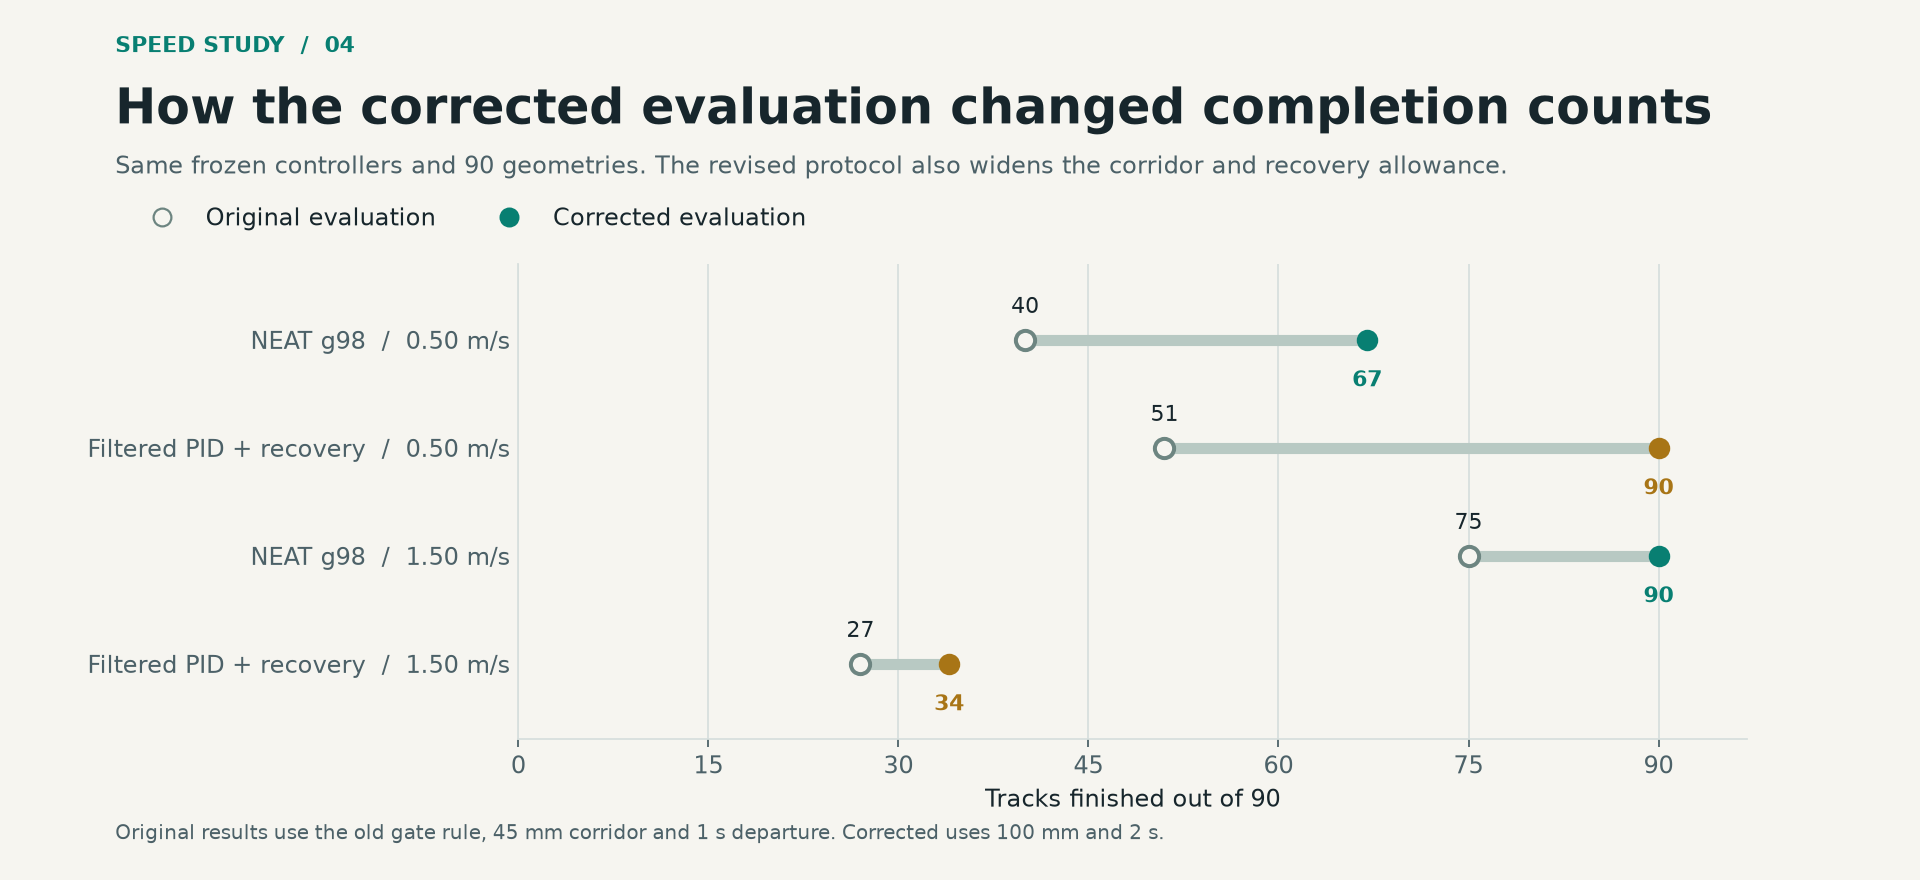

In [7]:
def correction_figure(groups, old):
    fig = page(4, "How the corrected evaluation changed completion counts",
               "Same frozen controllers and 90 geometries. The revised protocol also widens the corridor and recovery allowance.",
               "Original results use the old gate rule, 45 mm corridor and 1 s departure. Corrected uses 100 mm and 2 s.", 5.5)
    ax = fig.add_gridspec(1, 1, left=.27, right=.91, top=.70, bottom=.16).subplots()
    names = []
    for y, (p, cap) in enumerate(CONDITIONS):
        before = old[p, str(cap)]
        after = describe(groups[p, cap])["finished"]
        names.append(f"{label(p)}  /  {cap:.2f} m/s")
        ax.plot((before, after), (y, y), color="#b8c9c3", lw=5)
        ax.scatter(before, y, facecolor=BG, edgecolor="#6d8581", s=75, lw=1.8, zorder=3)
        ax.scatter(after, y, color=COLORS[p], s=75, zorder=4)
        ax.annotate(str(before), (before, y), (0, 12), textcoords="offset points", ha="center", fontsize=10)
        ax.annotate(str(after), (after, y), (0, -21), textcoords="offset points", ha="center",
                    color=COLORS[p], weight="bold", fontsize=10)
    ax.set(xlim=(0, 97), xticks=(0, 15, 30, 45, 60, 75, 90), xlabel="Tracks finished out of 90",
           yticks=range(4), yticklabels=names, ylim=(3.7, -.7))
    ax.set_axisbelow(True)
    ax.grid(axis="x")
    ax.tick_params(axis="y", length=0)
    fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=8, markerfacecolor=BG,
                               markeredgecolor="#6d8581", label="Original evaluation"),
                        Line2D([], [], ls="", marker="o", ms=8, color=TEAL, label="Corrected evaluation")],
               ncol=2, loc="upper left", bbox_to_anchor=(.06, .79), frameon=False)
    save(fig, "04-evaluation-correction")
old = {(r['policy'], r['cap']): r['finished'] for r in data['old']}
correction_figure(groups, old)

In [8]:
rows = []
for p, cap in CONDITIONS:
    r = describe(groups[p, cap])
    rows.append([label(p), f"{cap:.2f}", f"{r['finished']}/90", f"{r['rmse_mm']:.2f}", f"{r['progress_pct']:.1f}%"])
show_table(["Controller", "Cap (m/s)", "Finished", "RMSE (mm)", "Progress"], rows)

| Controller | Cap (m/s) | Finished | RMSE (mm) | Progress |
| --- | --- | --- | --- | --- |
| NEAT g98 | 0.50 | 67/90 | 18.88 | 87.4% |
| Filtered PID + recovery | 0.50 | 90/90 | 12.37 | 100.0% |
| NEAT g98 | 1.50 | 90/90 | 7.24 | 100.0% |
| Filtered PID + recovery | 1.50 | 34/90 | 101.50 | 57.6% |